# Interconnect: predicción de la baja de clientes (churn)

Interconnect quiere detectar con anticipación a los clientes que se darán de baja para ofrecerles promociones y planes especiales. Es un problema de **clasificación binaria**: ¿el cliente se dará de baja pronto? (`churn` = 1 / 0).

**Métrica principal:** AUC-ROC en test (meta ≥ 0.88). **Secundaria:** Recall, porque un falso negativo (un cliente que se va y el modelo no lo detecta) es ingreso perdido.

## Etapa 1: Plan de trabajo

1. **Unión y nulos.** `contract` LEFT JOIN `personal`, `internet` y `phone` por `customerID`. Un NaN después de la unión significa que el cliente no tiene ese servicio, no que falte el dato. Se rellena con `"No internet"` o `"No phone"` y no se elimina ninguna fila.
2. **Target.** `churn = 1` si `EndDate` es una fecha y `0` si es `"No"`.
3. **Preprocesamiento por variable.**
   - `BeginDate`/`EndDate` se convierten en `tenure_days`. Para los clientes activos se usa la fecha de corte, que se verifica en el EDA. Después se eliminan las fechas para evitar fugas de información.
   - `TotalCharges` es texto: se convierte a número y los vacíos se rellenan con 0.
   - Features nuevas: `has_internet`, `has_phone` y `n_services`.
   - Categóricas: One-Hot para la Regresión Logística, con las numéricas escaladas; OrdinalEncoder para Random Forest; categóricas nativas para LightGBM.
4. **Modelos.** Split estratificado 60/20/20 (train/validación/test).
   - Baseline sin balanceo: Regresión Logística, Random Forest y LightGBM.
   - Optimización: balanceo de clases (`class_weight` / `is_unbalance`) más `RandomizedSearchCV` con CV estratificada de 5 folds y `scoring="roc_auc"`.
   - Se elige el umbral en validación para alcanzar un Recall de alrededor de 0.80.
   - El modelo final se reentrena con train + validación y se evalúa **una sola vez** en test.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from src.data import load_raw, merge_tables, resolve_data_dir
from src.features import build_features

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 12345

## Etapa 2.1: Análisis exploratorio

In [2]:
data_dir = resolve_data_dir()
raw = load_raw(data_dir)
print("Datos desde:", data_dir)
for name, table in raw.items():
    print(f"\n=== {name}: {table.shape[0]} filas, {table.shape[1]} columnas, "
          f"customerID duplicados: {table['customerID'].duplicated().sum()}, "
          f"filas duplicadas: {table.duplicated().sum()}")
    table.info()
    display(table.head(3))

Datos desde: D:\Curso Ciencia de Datos\proyecto final\final_provider

=== contract: 7043 filas, 8 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   BeginDate         7043 non-null   str    
 2   EndDate           7043 non-null   str    
 3   Type              7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
dtypes: float64(1), str(7)
memory usage: 440.3 KB


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15



=== personal: 7043 filas, 5 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No



=== internet: 5517 filas, 8 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        5517 non-null   str  
 1   InternetService   5517 non-null   str  
 2   OnlineSecurity    5517 non-null   str  
 3   OnlineBackup      5517 non-null   str  
 4   DeviceProtection  5517 non-null   str  
 5   TechSupport       5517 non-null   str  
 6   StreamingTV       5517 non-null   str  
 7   StreamingMovies   5517 non-null   str  
dtypes: str(8)
memory usage: 344.9 KB


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No



=== phone: 6361 filas, 2 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     6361 non-null   str  
 1   MultipleLines  6361 non-null   str  
dtypes: str(2)
memory usage: 99.5 KB


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No


In [3]:
contract = raw["contract"]
begin_max = pd.to_datetime(contract["BeginDate"]).max()
end_max = pd.to_datetime(contract.loc[contract["EndDate"] != "No", "EndDate"]).max()
print("Último BeginDate:", begin_max.date(), "| Último EndDate:", end_max.date())
print("\nDistribución de EndDate entre los clientes que se fueron:")
print(contract.loc[contract["EndDate"] != "No", "EndDate"].value_counts().sort_index())
CUTOFF = "2020-02-01"
assert begin_max == pd.Timestamp(CUTOFF), "La fecha de corte no coincide con los datos"
assert end_max < pd.Timestamp(CUTOFF), "Hay bajas posteriores a la fecha de corte"

Último BeginDate: 2020-02-01 | Último EndDate: 2020-01-01

Distribución de EndDate entre los clientes que se fueron:
EndDate
2019-10-01 00:00:00    458
2019-11-01 00:00:00    485
2019-12-01 00:00:00    466
2020-01-01 00:00:00    460
Name: count, dtype: int64


In [4]:
total_num = pd.to_numeric(contract["TotalCharges"], errors="coerce")
blank = contract[total_num.isna()]
print(f"TotalCharges no numérico: {len(blank)} filas")
display(blank[["customerID", "BeginDate", "EndDate", "MonthlyCharges", "TotalCharges"]])

TotalCharges no numérico: 11 filas


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,52.55,
753,3115-CZMZD,2020-02-01,No,20.25,
936,5709-LVOEQ,2020-02-01,No,80.85,
1082,4367-NUYAO,2020-02-01,No,25.75,
1340,1371-DWPAZ,2020-02-01,No,56.05,
3331,7644-OMVMY,2020-02-01,No,19.85,
3826,3213-VVOLG,2020-02-01,No,25.35,
4380,2520-SGTTA,2020-02-01,No,20.00,
5218,2923-ARZLG,2020-02-01,No,19.70,
6670,4075-WKNIU,2020-02-01,No,73.35,


Todos los `TotalCharges` en blanco son de clientes con `BeginDate` igual a la fecha de corte (2020-02-01): acaban de contratar y todavía no se les ha facturado. Por eso se rellenan con **0**, que es el monto real acumulado. Usar `MonthlyCharges` supondría un pago que aún no ocurrió.

In [5]:
merged = merge_tables(raw)
print("Filas tras la unión:", len(merged))
print("\nNulos por columna tras la unión (= servicio no contratado):")
print(merged.isna().sum()[lambda s: s > 0])

Filas tras la unión: 7043

Nulos por columna tras la unión (= servicio no contratado):
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64


In [6]:
df = build_features(merged, CUTOFF)
df.info()
print("\nBalance de clases:")
print(df["churn"].value_counts().to_frame("clientes").assign(proporción=df["churn"].value_counts(normalize=True).round(3)))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Type              7043 non-null   str    
 1   PaperlessBilling  7043 non-null   str    
 2   PaymentMethod     7043 non-null   str    
 3   MonthlyCharges    7043 non-null   float64
 4   TotalCharges      7043 non-null   float64
 5   gender            7043 non-null   str    
 6   SeniorCitizen     7043 non-null   int64  
 7   Partner           7043 non-null   str    
 8   Dependents        7043 non-null   str    
 9   InternetService   7043 non-null   str    
 10  OnlineSecurity    7043 non-null   str    
 11  OnlineBackup      7043 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  MultipleLines     7043 non-null   str    
 17  churn 

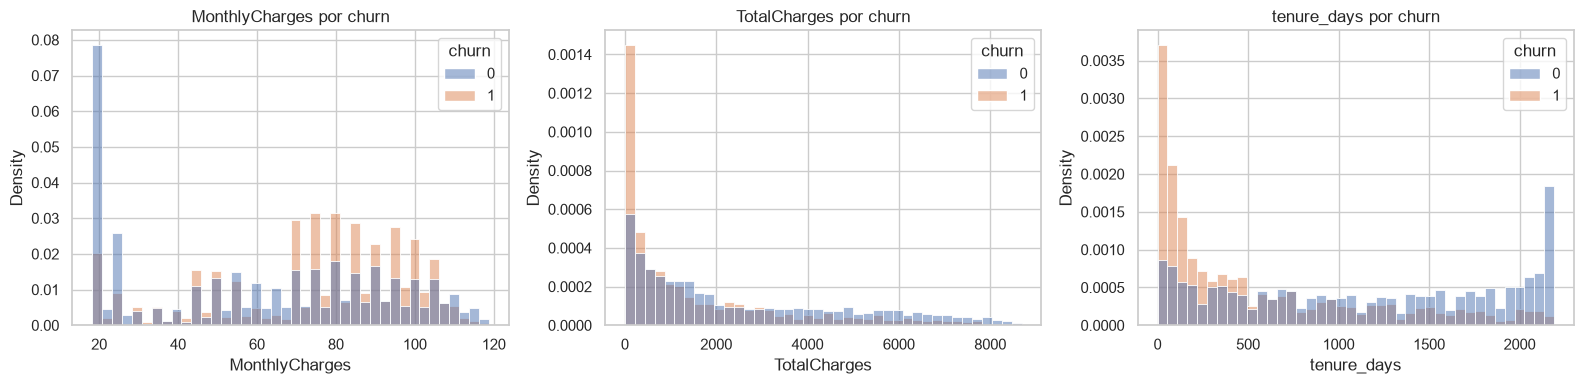

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["MonthlyCharges", "TotalCharges", "tenure_days"]):
    sns.histplot(data=df, x=col, hue="churn", stat="density", common_norm=False, bins=40, ax=ax)
    ax.set_title(f"{col} por churn")
plt.tight_layout()
plt.show()

In [8]:
print("Mediana por churn:")
display(df.groupby("churn")[["tenure_days", "MonthlyCharges"]].median())
churned = df.loc[df["churn"] == 1, "tenure_days"]
print(f"Bajas en los primeros 180 días: {(churned <= 180).mean():.1%}")
print(f"Bajas en el primer año (≤ 365 días): {(churned <= 365).mean():.1%}")

Mediana por churn:


,tenure_days,MonthlyCharges
churn,,
0,1157.0,64.425
1,304.0,79.650


Bajas en los primeros 180 días: 39.8%
Bajas en el primer año (≤ 365 días): 55.5%


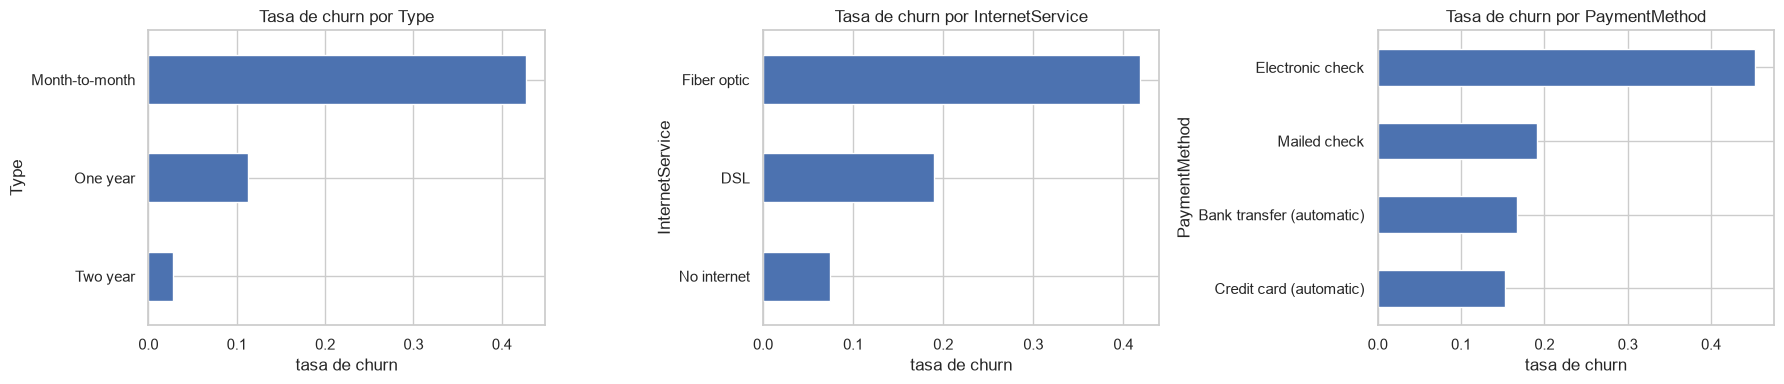

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["Type", "InternetService", "PaymentMethod"]):
    df.groupby(col)["churn"].mean().sort_values().plot.barh(ax=ax)
    ax.set_title(f"Tasa de churn por {col}")
    ax.set_xlabel("tasa de churn")
plt.tight_layout()
plt.show()

In [10]:
ratio = df["TotalCharges"] / df["MonthlyCharges"]
print("Correlación entre TotalCharges/MonthlyCharges y tenure_days:",
      round(np.corrcoef(ratio, df["tenure_days"])[0, 1], 4))

Correlación entre TotalCharges/MonthlyCharges y tenure_days: 0.9989


### Conclusiones del EDA

- **Desbalance moderado:** el 26.5% de los clientes se dio de baja (1869 de 7043). El split estratificado conservará esa proporción en train, validación y test.
- **Tipo de contrato:** es uno de los factores más claros. Los contratos mes a mes tienen una tasa de churn cercana al 43%, contra 11% en los de un año y 3% en los de dos años.
- **Servicio de internet y pago:** la fibra óptica (≈42%, contra ≈19% en DSL y ≈7% sin internet) y el cheque electrónico (≈45%) concentran las bajas. Los demás métodos de pago (cheque por correo y los dos automáticos) están entre 15% y 19%.
- **Permanencia:** la mediana de `tenure_days` es de 304 días en los clientes que se van, contra 1157 en los que se quedan, y más de la mitad de las bajas ocurre en el primer año. Los que se van también pagan cargos mensuales más altos (mediana de 79.65 contra 64.43).
- **Fechas:** todas las bajas ocurren entre 2019-10-01 y 2020-01-01, y el último `BeginDate` es 2020-02-01, que confirma la fecha de corte. Por eso las fechas no se usan como features (solo `tenure_days`).
- **Razón `TotalCharges / MonthlyCharges`:** su correlación con `tenure_days` es 0.9989 (≥ 0.95), así que **no se agrega**: sería redundante.

**Nota sobre la Regresión Logística:** `has_internet` y `has_phone` repiten la información de las categorías `"No internet"` / `"No phone"` del One-Hot. La colinealidad no impide el ajuste gracias a la regularización L2, pero los coeficientes de esas columnas no se interpretan por separado.

## Etapa 2.2: Preprocesamiento y división de los datos

In [11]:
X = df.drop(columns="churn")
y = df["churn"]
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=RANDOM_STATE)
for name, part, target in [("train", X_train, y_train), ("valid", X_valid, y_valid), ("test", X_test, y_test)]:
    print(f"{name}: {part.shape}, churn = {target.mean():.3f}")

train: (4225, 21), churn = 0.265
valid: (1409, 21), churn = 0.265
test: (1409, 21), churn = 0.265


In [12]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

# Regresión logística: One-Hot (sin orden artificial) + escalado (coeficientes comparables y convergencia).
# drop="if_binary" deja una sola columna en las variables Sí/No y evita duplicar información.
ohe_prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
# Random Forest: los árboles no necesitan escalado y OrdinalEncoder evita multiplicar columnas.
ord_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", "passthrough", num_cols),
])
# LightGBM: categóricas nativas. Las categorías se fijan solo con train.
cat_dtypes = {c: pd.CategoricalDtype(sorted(X_train[c].unique())) for c in cat_cols}
X_train_lgb, X_valid_lgb, X_test_lgb = (part.astype(cat_dtypes) for part in (X_train, X_valid, X_test))

Categóricas: ['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
Numéricas: ['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'tenure_days', 'has_internet', 'has_phone', 'n_services']


In [13]:
def evaluate(model, X, y, threshold=0.5):
    """AUC-ROC (con probabilidades) y Recall/Precisión con el umbral dado."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "AUC-ROC": roc_auc_score(y, proba),
        "Recall": recall_score(y, pred),
        "Precisión": precision_score(y, pred, zero_division=0),
    }

## Etapa 2.3: Modelos baseline (sin balanceo)

Tres modelos con parámetros por defecto, entrenados en train y evaluados en validación con umbral 0.5.

In [14]:
def make_logreg(**kw):
    return Pipeline([("prep", clone(ohe_prep)),
                     ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw))])

def make_rf(n_jobs=-1, **kw):
    return Pipeline([("prep", clone(ord_prep)),
                     ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=n_jobs, **kw))])

def make_lgbm(n_jobs=-1, **kw):
    return LGBMClassifier(random_state=RANDOM_STATE, n_jobs=n_jobs, verbose=-1, **kw)

DATA = {
    "LogisticRegression": (X_train, X_valid, X_test),
    "RandomForest": (X_train, X_valid, X_test),
    "LightGBM": (X_train_lgb, X_valid_lgb, X_test_lgb),
}
candidates, rows = {}, []
for name, model in {"LogisticRegression": make_logreg(), "RandomForest": make_rf(), "LightGBM": make_lgbm()}.items():
    X_tr, X_va, _ = DATA[name]
    model.fit(X_tr, y_train)
    candidates[(name, "baseline")] = model
    rows.append({"modelo": name, "etapa": "baseline", "AUC-ROC CV": np.nan, **evaluate(model, X_va, y_valid)})
results = pd.DataFrame(rows)
results.round(4)

,modelo,etapa,AUC-ROC CV,AUC-ROC,Recall,Precisión
0,LogisticRegression,baseline,NaN,0.8570,0.5401,0.6801
1,RandomForest,baseline,NaN,0.8511,0.5401,0.7214
2,LightGBM,baseline,NaN,0.9013,0.6230,0.7767


## Etapa 2.4: Balanceo de clases + búsqueda de hiperparámetros

El churn es la clase minoritaria (cerca de 26%), así que se aplica **ponderación de clases** (`class_weight="balanced"`; en LightGBM, `is_unbalance=True`). Así se penalizan más los errores sobre los clientes que se van, sin duplicar ni descartar filas. La búsqueda usa `RandomizedSearchCV` con CV estratificada de 5 folds sobre train y `scoring="roc_auc"`.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search_spaces = {
    "LogisticRegression": (
        make_logreg(class_weight="balanced"),
        {"model__C": loguniform(1e-3, 1e2)},
        30,
    ),
    "RandomForest": (
        make_rf(n_jobs=1, class_weight="balanced"),
        {"model__n_estimators": randint(200, 801),
         "model__max_depth": [None, 6, 8, 10, 12, 16, 20],
         "model__min_samples_leaf": randint(1, 21),
         "model__max_features": ["sqrt", "log2", 0.5]},
        30,
    ),
    "LightGBM": (
        make_lgbm(n_jobs=1, is_unbalance=True, subsample_freq=1),
        {"n_estimators": randint(200, 1501),
         "learning_rate": loguniform(0.01, 0.2),
         "num_leaves": randint(8, 65),
         "min_child_samples": randint(5, 61),
         "subsample": uniform(0.6, 0.4),
         "colsample_bytree": uniform(0.6, 0.4),
         "reg_lambda": loguniform(1e-3, 10)},
        50,
    ),
}
searches = {}
for name, (estimator, params, n_iter) in search_spaces.items():
    X_tr, X_va, _ = DATA[name]
    search = RandomizedSearchCV(estimator, params, n_iter=n_iter, scoring="roc_auc",
                                cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_tr, y_train)
    searches[name] = search
    candidates[(name, "optimizado")] = search.best_estimator_
    rows.append({"modelo": name, "etapa": "optimizado", "AUC-ROC CV": search.best_score_,
                 **evaluate(search.best_estimator_, X_va, y_valid)})
    print(f"{name}: mejores parámetros {search.best_params_}")
results = pd.DataFrame(rows)

LogisticRegression: mejores parámetros {'model__C': np.float64(0.2177684881685945)}


RandomForest: mejores parámetros {'model__max_depth': 8, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 445}


LightGBM: mejores parámetros {'colsample_bytree': np.float64(0.7044505159946781), 'learning_rate': np.float64(0.019727397180640458), 'min_child_samples': 13, 'n_estimators': 1216, 'num_leaves': 15, 'reg_lambda': np.float64(0.17657775897730493), 'subsample': np.float64(0.9269166147562844)}


In [16]:
results.pivot_table(index="modelo", columns="etapa",
                    values=["AUC-ROC CV", "AUC-ROC", "Recall", "Precisión"]).round(4)

AUC-ROC            AUC-ROC CV Precisión             \
etapa              baseline optimizado optimizado  baseline optimizado   
modelo                                                                   
LightGBM             0.9013     0.9075     0.8922    0.7767     0.6705   
LogisticRegression   0.8570     0.8564     0.8427    0.6801     0.5450   
RandomForest         0.8511     0.8755     0.8580    0.7214     0.5960   

                     Recall             
etapa              baseline optimizado  
modelo                                  
LightGBM             0.6230     0.7781  
LogisticRegression   0.5401     0.8102  
RandomForest         0.5401     0.7968

### Comparación baseline vs. optimizado

- **LightGBM es el mejor modelo** en las dos etapas: AUC-ROC en validación de 0.9013 (baseline) y 0.9075 (optimizado), por encima de la meta de 0.88. Random Forest optimizado queda en 0.8755 y la Regresión Logística en ≈0.857.
- **El balanceo sube mucho el Recall** con umbral 0.5: LightGBM pasa de 0.6230 a 0.7781, Random Forest de 0.5401 a 0.7968 y la Regresión Logística de 0.5401 a 0.8102. A cambio, la precisión baja (LightGBM: de 0.7767 a 0.6705), porque se marcan más clientes como "en riesgo".
- **La búsqueda de hiperparámetros** mejora sobre todo a Random Forest (+0.024 de AUC). En la Regresión Logística no cambia el AUC (0.8570 → 0.8564): el balanceo mueve el umbral efectivo, pero no el orden de las probabilidades.
- **La CV coincide con validación:** el AUC de CV queda entre 0.014 y 0.018 por debajo del de validación en los tres modelos. No hay señales de sobreajuste ni de fuga de datos.